# 05 · Card-history features (model 2.0.2)

The error analysis in notebook 03 found a single blind spot behind both error types. The network scored each purchase on its own, so it could not tell that a small purchase came in the middle of a fraud burst (most missed frauds), nor that a large purchase came from a card with a calm history (most false alarms).

Model 2.0.2 adds five features describing what the same card did **before** each purchase, computed by `fraud_core.history`:

| Feature | Meaning |
|---|---|
| `tx_last_24h` | purchases on the card in the previous 24 hours |
| `night_tx_last_24h` | of those, how many between 22h and 3h |
| `large_tx_last_24h` | of those, how many above \$200 |
| `amt_last_24h` | amount spent on the card in the previous 24 hours (log-compressed) |
| `hours_since_prev` | hours since the card's previous purchase (log-compressed, capped at 30 days) |

Only strictly earlier purchases of the same card are counted, and no fraud labels are used. That is exactly what a bank knows when a purchase arrives, so nothing leaks from the future. The serving API computes the same numbers one purchase at a time, and a test checks that both computations agree exactly.

This notebook compares the two **published** bundles, `models/1.0.2` and `models/2.0.2`, on the cv set. Nothing is retrained here.

In [1]:
from pathlib import Path

# Reload the project packages automatically, so code edits show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from fraud_core.history import HISTORY_COLUMNS, card_history
from fraud_core.model import FraudModel
from fraud_training.data import ROOT, load_raw, split_by_time
from fraud_training.error_analysis import NIGHT_HOURS, count_tags, sample_errors
from fraud_training.evaluate import cost_by_threshold, evaluate, plot_pr_curves, results_table

In [3]:
df = load_raw()
df = df.join(card_history(df))  # the whole timeline at once; each purchase sees only earlier ones
split = split_by_time(df)
cv = split.cv

## What the new features say

Average value of each feature on the training set, for legit purchases and frauds:

In [4]:
split.train.groupby("is_fraud")[HISTORY_COLUMNS].mean().rename(index={0: "legit", 1: "fraud"}).round(2).T

is_fraud,legit,fraud
tx_last_24h,4.10,4.30
night_tx_last_24h,0.93,3.26
large_tx_last_24h,0.19,2.84
amt_last_24h,280.06,1950.47
hours_since_prev,9.31,12.94


A fraudulent purchase typically follows about three large purchases and three night purchases on the same card within the previous day, and about \$1,950 of spending. A legit one follows fewer than one night purchase, almost no large ones and about \$280. The *number* of recent purchases is nearly the same for both: frauds do not come with more purchases, they come with different ones. The information was in the data all along; it just was not in the model's inputs.

## The two published models on cv

In [5]:
models = {version: FraudModel.load(ROOT.parent / "models" / version) for version in ["1.0.2", "2.0.2"]}
y_cv = cv["is_fraud"].to_numpy()
probs = {f"model {v}": m.predict_proba(cv) for v, m in models.items()}
results_table({name: evaluate(y_cv, p) for name, p in probs.items()})

,accuracy,precision,recall,f1,pr_auc,roc_auc
model 2.0.2,0.9985,0.8275,0.9650,0.8910,0.9735,0.9992
model 1.0.2,0.9970,0.7183,0.8412,0.7749,0.8755,0.9964


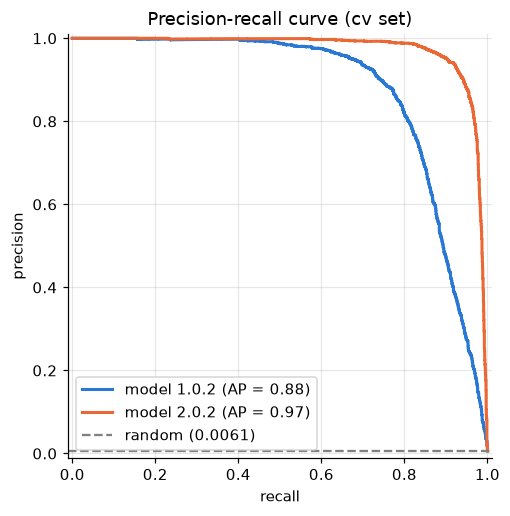

In [6]:
ax = plot_pr_curves(y_cv, probs)
ax.figure.savefig(FIGURES / "pr_curve_v1_v2.png", bbox_inches="tight")

The table uses the default 0.5 threshold for precision and recall. PR-AUC, which does not depend on the threshold, measures the ranking itself.

A single training run can be lucky, so `fraud_training.compare_card_history` trains both feature sets with three seeds each:

In [7]:
runs = pd.read_csv(ROOT / "reports" / "card_history_search.csv")
runs.groupby("features", sort=False)[["pr_auc", "missed_frauds", "false_alarms", "total_cost"]].agg(["mean", "std"]).round(3)

pr_auc        missed_frauds         false_alarms  \
                             mean    std          mean     std         mean   
features                                                                      
transaction only            0.855  0.022       230.333  31.342     2824.333   
transaction + card history  0.966  0.011        54.667  13.051      989.333   

                                    total_cost            
                                std       mean       std  
features                                                  
transaction only            178.981  44310.663  2917.694  
transaction + card history  216.809  21651.023  3138.018

## Cost at each model's own threshold

Each bundle carries the threshold chosen by cost on cv when it was trained, which is the decision the API actually makes:

In [8]:
amounts = cv["amt"].to_numpy()
decisions = {}
for version, model in models.items():
    p = probs[f"model {version}"]
    row = cost_by_threshold(y_cv, p, amounts, false_alarm_cost=model.metadata["decision_cost"]["false_alarm_cost"],
                            thresholds=np.array([model.threshold])).iloc[0]
    decisions[f"model {version}"] = {
        "threshold": model.threshold,
        "missed frauds": int(row["missed_frauds"]),
        "amount lost to missed frauds": round(row["missed_fraud_cost"]),
        "false alarms": int(row["false_alarms"]),
        "total cost": round(row["total_cost"]),
    }
pd.DataFrame(decisions)

,model 1.0.2,model 2.0.2
threshold,0.23,0.35
missed frauds,204.00,56.00
amount lost to missed frauds,17942.00,14397.00
false alarms,2722.00,752.00
total cost,45162.00,21917.00


## Error analysis, again

The same two tags that pointed to card history in notebook 03, now counted on all the errors each model makes at its own threshold:

In [9]:
large_recently = cv["large_tx_last_24h"] >= 1
rows = {}
for version, model in models.items():
    flagged = probs[f"model {version}"] >= model.threshold
    missed = cv[(y_cv == 1) & ~flagged]
    false_alarms = cv[(y_cv == 0) & flagged]
    rows[f"model {version}"] = {
        "missed frauds": len(missed),
        "of which: card already in a burst": int(large_recently.loc[missed.index].sum()),
        "false alarms": len(false_alarms),
        "of which: calm card history": int((~large_recently).loc[false_alarms.index].sum()),
    }
pd.DataFrame(rows)

,model 1.0.2,model 2.0.2
missed frauds,204,56
of which: card already in a burst,194,20
false alarms,2722,752
of which: calm card history,2316,310


And the course recipe on model 2.0.2's remaining missed frauds, with the same tags as before. Only 56 are left, so the sample is all of them:

In [10]:
flagged_v2 = probs["model 2.0.2"] >= models["2.0.2"].threshold
missed_v2 = cv[(y_cv == 1) & ~flagged_v2]
night = cv["trans_date_trans_time"].dt.hour.isin(NIGHT_HOURS)
count_tags(sample_errors(missed_v2), {
    "small purchase (under $100)": cv["amt"] < 100,
    "daytime (4h to 21h)": ~night,
    "card already in a burst (large purchase in the last 24h)": large_recently,
    "first fraud on the card (no purchase in the last 24h)": cv["tx_last_24h"] == 0,
})

,errors,share_%
small purchase (under $100),33,58.9
daytime (4h to 21h),25,44.6
card already in a burst (large purchase in the last 24h),20,35.7
first fraud on the card (no purchase in the last 24h),5,8.9


## Conclusions

- **The ranking improves far beyond the noise.** Across three seeds, PR-AUC on cv rises from 0.855 ± 0.022 without card history to 0.966 ± 0.011 with it. The published 2.0.2 bundle scores 0.973.
- **Both error types fall together.** At its own cost-based threshold, model 2.0.2 misses 56 frauds instead of 204 and raises 752 false alarms instead of 2,722. Moving the threshold alone can only trade one error for the other; reducing both needs better information, which is what the new features add. The total cost on cv falls from \$45,162 to \$21,917, about half.
- **The analysis predicted where the gains would come from.** Missed frauds made while the card was already in a burst fall from 194 to 20, and false alarms on cards with a calm history fall from 2,316 to 310.
- **What is left.** The 56 remaining missed frauds are mostly small (59%) and almost half happen during the day; only a third now fall inside a visible burst. They are larger on average than before (about \$257 against \$88), so the amount lost to missed frauds falls less than their number, from \$17,942 to \$14,397. A new round of error analysis would start from them.
- **Caveats.** The simulator makes every compromised card follow the same short burst, so real data would show a smaller gain. Serving needs each card's recent purchases: the API keeps them in memory, so a fresh instance sees every card as quiet until it has seen some traffic. The hyperparameters and the threshold were tuned on cv, so these numbers are slightly optimistic; the test set is still untouched.